# Bypass vs. baseline

Does routing small flows on shorter paths cut their tail latency, what does it cost other traffic, and at what load does the cost outweigh the gain?

Reads the baseline and bypass runs of the sweep set by `SWEEP` in `common.py`. It only compares a load and seed once the baseline and every bypass mode have finished it.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import common

common.setup_plots()
pd.options.display.float_format = "{:,.2f}".format

print(f"Reading {common.MACHINE}/{common.BATCH}")
baseline = common.load_runs(common.BASELINE_EXPERIMENT)
bypass = common.load_runs(common.BYPASS_EXPERIMENT)

# Keep only loads and seeds that the baseline and every bypass mode have finished, so
# that all modes in a table cover the same flows.
pairs = {(r.load, r.seed) for r in baseline}
for mode in {r.bypass for r in bypass}:
    pairs &= {(r.load, r.seed) for r in bypass if r.bypass == mode}
if not bypass:
    pairs = set()
runs = [r for r in baseline + bypass if (r.load, r.seed) in pairs]
ready = bool(pairs)
if ready:
    flows = common.load_flows(runs)
    links = common.load_links(runs)
    print(f"Comparing {len(pairs)} load and seed pairs: {sorted(pairs)}")
    modes = [m for m in common.MODES if m in {r.bypass for r in runs}]
    print(f"Modes: {modes}")
else:
    print(f"Nothing to compare yet: {len(baseline)} baseline runs and {len(bypass)} bypass runs share no load and seed.")
    print(f"Run experiments/{common.BASELINE_EXPERIMENT}.sh and experiments/{common.BYPASS_EXPERIMENT}.sh.")

Reading remote/2026-11-07_120750_5770a94


Comparing 9 load and seed pairs: [(0.1, 561), (0.1, 562), (0.1, 563), (0.3, 561), (0.3, 562), (0.3, 563), (0.5, 561), (0.5, 562), (0.5, 563)]
Modes: ['none', 'adjacent', 'shortest']


## Are the runs healthy and comparable?

Every mode must run the same flows, or the comparison means nothing.

In [2]:
if ready:
    display(common.runs_table(runs))
    identity = ["flow", "source_router", "destination_router", "bytes", "start_ns"]
    mismatches = 0
    for key, group in flows.groupby(["load", "seed"]):
        reference = group[group["bypass"] == "none"][identity].reset_index(drop=True)
        for mode, other in group.groupby("bypass"):
            if not reference.equals(other[identity].reset_index(drop=True)):
                print(f"Different flows at load and seed {key}, mode {mode}")
                mismatches += 1
    print("All modes run the same flows" if mismatches == 0 else f"{mismatches} mismatches")

,run,bypass,load,seed,flows,unfinished,ttl_drops,no_route_drops,queue_drops,wall_minutes,peak_memory_mb,commit
0,load-0.1_seed-561,none,0.10,561,47088,0,0,0,170,7.50,828.40,bdd4cb8
1,load-0.1_seed-562,none,0.10,562,46997,0,0,0,142,11.70,825.50,bdd4cb8
2,load-0.1_seed-563,none,0.10,563,47024,0,0,0,188,7.40,813.50,bdd4cb8
3,load-0.3_seed-561,none,0.30,561,140825,0,0,0,16332,29.10,"2,360.90",bdd4cb8
4,load-0.3_seed-562,none,0.30,562,140876,0,0,0,16411,31.60,"2,373.60",bdd4cb8
5,load-0.3_seed-563,none,0.30,563,140820,0,0,0,15742,29.10,"2,401.30",bdd4cb8
6,load-0.5_seed-561,none,0.50,561,234933,0,0,0,122427,56.90,"4,121.40",bdd4cb8
7,load-0.5_seed-562,none,0.50,562,234811,0,0,0,126087,61.60,"4,121.10",bdd4cb8
8,load-0.5_seed-563,none,0.50,563,235206,0,0,0,123562,56.20,"4,137.00",bdd4cb8
9,adjacent_load-0.1_seed-561,adjacent,0.10,561,47088,0,0,0,166,7.40,828.20,bdd4cb8


All modes run the same flows


## H1: Does the bypass cut small-flow latency?

Expect the biggest gain for small flows between adjacent routers, since they cross one queue instead of two to five.

### Path lengths

Mean fabric hops of delivered packets, including ACKs. The adjacent bypass should take small flows between neighbors to 1 hop, and the shortest-path bypass should also shorten the paths of other small flows. Large flows should not change.

In [3]:
if ready:
    display(common.mean_hops_table(runs))

load                     0.10  0.30  0.50
class          bypass                    
large          adjacent  3.62  3.62  3.61
               none      3.62  3.62  3.61
               shortest  3.62  3.62  3.61
small_adjacent adjacent  1.00  1.00  1.00
               none      3.30  3.30  3.30
               shortest  1.00  1.00  1.00
small_other    adjacent  3.65  3.65  3.64
               none      3.65  3.65  3.64
               shortest  2.36  2.36  2.36

In [4]:
if ready:
    display(common.fct_table(flows, ["class", "load", "bypass"]))

flows  unfinished    p50      p99     p99.9  \
class          load bypass                                                   
large          0.10 adjacent   11402           0 180.24   283.80    379.77   
                    none       11402           0 180.35   283.11    356.96   
                    shortest   11402           0 179.87   281.83    378.53   
               0.30 adjacent   33922           0 257.71   573.53  1,463.54   
                    none       33922           0 258.01   569.81 10,094.67   
                    shortest   33922           0 255.43   559.95  1,458.56   
               0.50 adjacent   56536           0 413.63 1,460.52 10,159.31   
                    none       56536           0 413.62 1,439.63 10,159.31   
                    shortest   56536           0 405.83 1,409.07 10,159.31   
small_adjacent 0.10 adjacent    6367           0   5.67    11.25     19.51   
                    none        6367           0   9.99    16.83     24.90   
                    shortest    6367           0   5.67    11.11     19.62   
               0.30 adjacent   18947           0   6.51    23.36  1,029.90   
                    none       18947           0  11.63    31.56  1,054.41   
                    shortest   18947           0   6.50    23.52     48.84   
               0.50 adjacent   31558           0   9.22    47.05 10,005.60   
                    none       31558           0  16.89 1,043.07 10,010.49   
                    shortest   31558           0   9.28    47.29 10,005.60   
small_other    0.10 adjacent   94962           0  10.52    17.62     25.52   
                    none       94962           0  10.52    17.58     25.68   
                    shortest   94962           0   7.93    14.75     21.82   
               0.30 adjacent  284979           0  12.25    33.33  1,056.74   
                    none      284979           0  12.26    33.36  1,063.13   
                    shortest  284979           0   9.61    28.84  1,038.35   
               0.50 adjacent  475840           0  18.02 1,046.00 10,010.49   
                    none      475840           0  18.06 1,048.17 10,010.49   
                    shortest  475840           0  13.71    70.40 10,008.86   

                              beyond_p99  
class          load bypass                
large          0.10 adjacent         114  
                    none             114  
                    shortest         114  
               0.30 adjacent         339  
                    none             339  
                    shortest         339  
               0.50 adjacent         565  
                    none             565  
                    shortest         565  
small_adjacent 0.10 adjacent          63  
                    none              63  
                    shortest          63  
               0.30 adjacent         189  
                    none             189  
                    shortest         189  
               0.50 adjacent         315  
                    none             315  
                    shortest         315  
small_other    0.10 adjacent         949  
                    none             949  
                    shortest         949  
               0.30 adjacent        2849  
                    none            2849  
                    shortest        2849  
               0.50 adjacent        4758  
                    none            4758  
                    shortest        4758

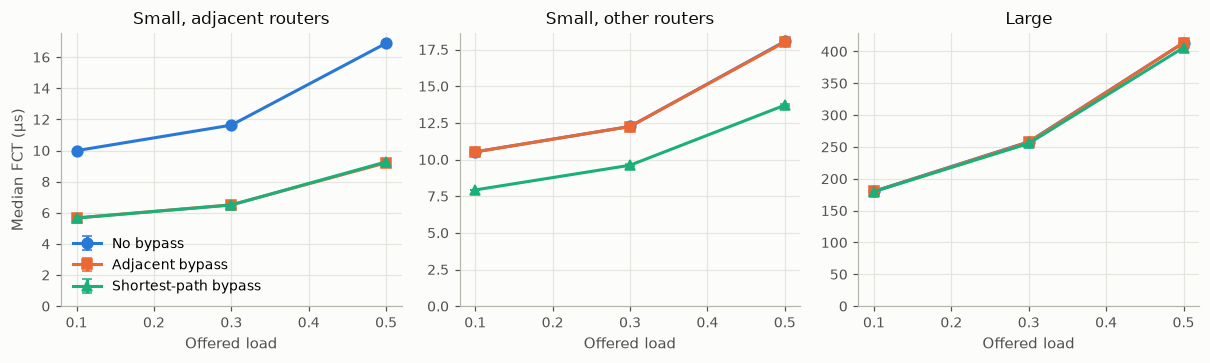

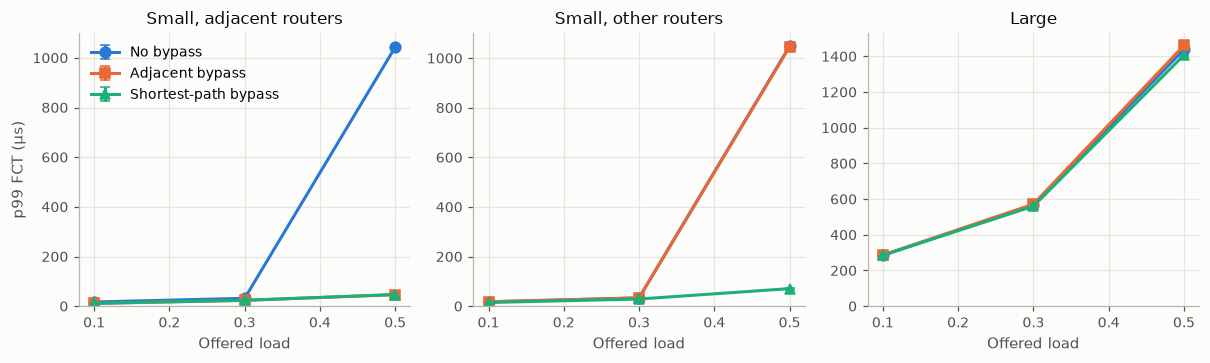

In [5]:
if ready:
    common.plot_metric_by_mode(flows, "p50", "Median FCT (µs)")
    common.plot_metric_by_mode(flows, "p99", "p99 FCT (µs)")

### Flow by flow

Since every mode runs the same flows, each flow can be compared with itself. A ratio below 1 means the bypass made that flow faster.

In [6]:
if ready:
    keys = ["load", "seed", "flow"]
    reference = flows[flows["bypass"] == "none"][keys + ["fct_us"]].rename(columns={"fct_us": "baseline_us"})
    paired = flows[flows["bypass"] != "none"].merge(reference, on=keys)
    paired["ratio"] = paired["fct_us"] / paired["baseline_us"]
    display(
        paired.groupby(["class", "load", "bypass"]).agg(
            median_ratio=("ratio", "median"),
            faster=("ratio", lambda r: (r < 1).mean()),
            slower=("ratio", lambda r: (r > 1).mean()),
        )
    )

median_ratio  faster  slower
class          load bypass                                
large          0.10 adjacent          1.00    0.52    0.48
                    shortest          1.00    0.56    0.44
               0.30 adjacent          1.00    0.51    0.49
                    shortest          0.99    0.58    0.42
               0.50 adjacent          1.00    0.51    0.49
                    shortest          0.98    0.56    0.44
small_adjacent 0.10 adjacent          0.59    0.99    0.00
                    shortest          0.59    1.00    0.00
               0.30 adjacent          0.59    0.97    0.03
                    shortest          0.59    0.97    0.03
               0.50 adjacent          0.60    0.91    0.09
                    shortest          0.60    0.91    0.09
small_other    0.10 adjacent          1.00    0.43    0.43
                    shortest          0.78    0.95    0.05
               0.30 adjacent          1.00    0.50    0.50
                    shortest          0.78    0.85    0.15
               0.50 adjacent          1.00    0.50    0.50
                    shortest          0.78    0.75    0.25

### Why: fewer timeouts

A small flow's p99 is about 1,000 µs once more than 1% of its flows wait for a retransmission timeout, and much less otherwise: see the baseline notebook. So a bypass that brings that share under 1% cuts the p99 by a lot even if queueing barely changes. `any_timeout_pct` is the percentage that waited for any timeout, and `clean_p99` is the p99 of the rest, which is the queueing alone.

In [7]:
if ready:
    display(common.timeout_table(flows, ["class", "load", "bypass"]))

flows  data_timeout_pct  handshake_timeout_pct  \
class          load bypass                                                      
small_adjacent 0.10 adjacent    6367              0.00                   0.00   
                    none        6367              0.00                   0.02   
                    shortest    6367              0.00                   0.00   
               0.30 adjacent   18947              0.11                   0.04   
                    none       18947              0.17                   0.07   
                    shortest   18947              0.05                   0.03   
               0.50 adjacent   31558              0.37                   0.26   
                    none       31558              0.78                   0.54   
                    shortest   31558              0.45                   0.20   
small_other    0.10 adjacent   94962              0.00                   0.00   
                    none       94962              0.00                   0.00   
                    shortest   94962              0.00                   0.00   
               0.30 adjacent  284979              0.16                   0.08   
                    none      284979              0.18                   0.09   
                    shortest  284979              0.12                   0.05   
               0.50 adjacent  475840              0.86                   0.47   
                    none      475840              0.87                   0.51   
                    shortest  475840              0.61                   0.33   

                              any_timeout_pct  clean_p50  clean_p99  clean_max  
class          load bypass                                                      
small_adjacent 0.10 adjacent             0.00       5.67      11.25      33.82  
                    none                 0.02       9.99      16.77      58.04  
                    shortest             0.00       5.67      11.11      33.77  
               0.30 adjacent             0.15       6.51      22.61      50.03  
                    none                 0.25      11.63      30.30      78.83  
                    shortest             0.08       6.50      23.21      69.76  
               0.50 adjacent             0.63       9.17      38.50     149.78  
                    none                 1.32      16.77      49.00     150.69  
                    shortest             0.65       9.23      38.92     106.17  
small_other    0.10 adjacent             0.00      10.52      17.61      50.17  
                    none                 0.01      10.52      17.56      39.97  
                    shortest             0.00       7.93      14.74      36.57  
               0.30 adjacent             0.24      12.24      31.90      98.16  
                    none                 0.27      12.25      31.89     100.34  
                    shortest             0.17       9.61      27.93      85.63  
               0.50 adjacent             1.34      17.88      50.53     169.86  
                    none                 1.38      17.92      50.35     191.27  
                    shortest             0.94      13.62      44.64     138.16

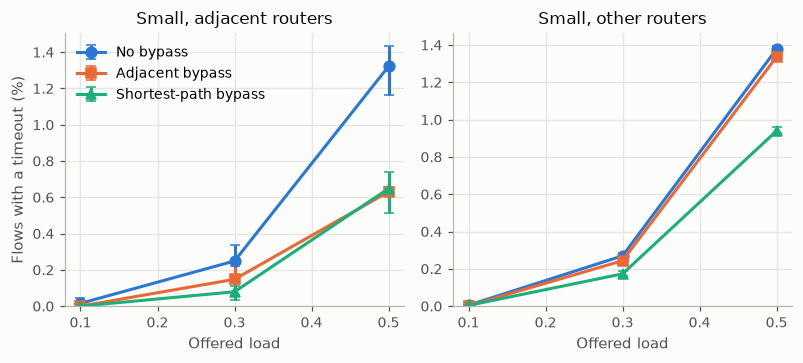

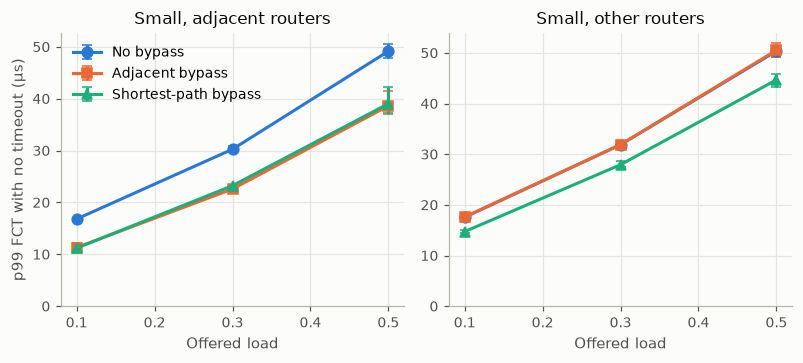

In [8]:
if ready:
    common.plot_metric_by_mode(
        flows, "any_timeout_pct", "Flows with a timeout (%)", table=common.timeout_table, classes=common.SMALL_CLASSES
    )
    common.plot_metric_by_mode(
        flows, "clean_p99", "p99 FCT with no timeout (µs)", table=common.timeout_table, classes=common.SMALL_CLASSES
    )

### Seed by seed

Pooled numbers can hide a change that only some seeds show. Each row compares every seed's bypass run with the baseline run on the same flows: `seeds_fewer_timeouts` counts the seeds where the bypass cut the timeout rate, `timeout_pts` is the change in percentage points, and the `clean_` columns are percent changes. A change with the same sign in every seed is unlikely to be noise.

In [9]:
if ready:
    display(common.seed_change_table(flows))

seeds  seeds_fewer_timeouts  timeout_pts_mean  \
class          load bypass                                                    
small_adjacent 0.10 adjacent      3                     1             -0.02   
                    shortest      3                     1             -0.02   
               0.30 adjacent      3                     3             -0.10   
                    shortest      3                     3             -0.17   
               0.50 adjacent      3                     3             -0.69   
                    shortest      3                     3             -0.67   
small_other    0.10 adjacent      3                     2             -0.00   
                    shortest      3                     1             -0.00   
               0.30 adjacent      3                     3             -0.03   
                    shortest      3                     3             -0.10   
               0.50 adjacent      3                     3             -0.04   
                    shortest      3                     3             -0.44   

                              timeout_pts_min  timeout_pts_max  \
class          load bypass                                       
small_adjacent 0.10 adjacent            -0.05             0.00   
                    shortest            -0.05             0.00   
               0.30 adjacent            -0.18            -0.02   
                    shortest            -0.24            -0.13   
               0.50 adjacent            -0.81            -0.51   
                    shortest            -0.85            -0.42   
small_other    0.10 adjacent            -0.01             0.00   
                    shortest            -0.01             0.00   
               0.30 adjacent            -0.05            -0.01   
                    shortest            -0.12            -0.07   
               0.50 adjacent            -0.06            -0.01   
                    shortest            -0.46            -0.43   

                              clean_p50_pct_mean  clean_p99_pct_mean  \
class          load bypass                                             
small_adjacent 0.10 adjacent              -43.25              -32.73   
                    shortest              -43.31              -33.45   
               0.30 adjacent              -44.01              -25.32   
                    shortest              -44.11              -23.21   
               0.50 adjacent              -45.27              -21.49   
                    shortest              -44.99              -20.65   
small_other    0.10 adjacent               -0.02                0.34   
                    shortest              -24.67              -16.11   
               0.30 adjacent               -0.04                0.12   
                    shortest              -21.56              -12.36   
               0.50 adjacent               -0.22                0.31   
                    shortest              -24.00              -11.29   

                              clean_p99_pct_min  clean_p99_pct_max  
class          load bypass                                          
small_adjacent 0.10 adjacent             -38.32             -27.37  
                    shortest             -37.25             -29.70  
               0.30 adjacent             -27.78             -23.17  
                    shortest             -24.46             -22.13  
               0.50 adjacent             -23.84             -18.10  
                    shortest             -22.97             -16.70  
small_other    0.10 adjacent              -0.04               0.74  
                    shortest             -16.76             -15.42  
               0.30 adjacent              -0.42               0.67  
                    shortest             -13.09             -11.42  
               0.50 adjacent              -0.42               1.52  
                    shortest             -12.06             -10.45

## H2: What does it cost, and where is the crossover?

Each ratio is a bypass mode's p99 over the baseline's at the same load. Above 1 means the bypass made that class's tail worse. The crossover is the load where a small-flow ratio passes 1, and a large-flow ratio above 1 shows the cost to other traffic.

In [10]:
if ready:
    p99 = common.fct_table(flows, ["class", "load", "bypass"])["p99"].unstack("bypass")
    ratios = pd.DataFrame({mode: p99[mode] / p99["none"] for mode in p99.columns if mode != "none"})
    display(ratios)

adjacent  shortest
class          load                    
large          0.10      1.00      1.00
               0.30      1.01      0.98
               0.50      1.01      0.98
small_adjacent 0.10      0.67      0.66
               0.30      0.74      0.75
               0.50      0.05      0.05
small_other    0.10      1.00      0.84
               0.30      1.00      0.86
               0.50      1.00      0.07

### Large-flow throughput

The cost H2 expects: if bypassed small flows crowd the links large flows use, large-flow goodput drops, the slowest flows (`p1`) first. Ratios are each bypass mode over the baseline at the same load.

In [11]:
if ready:
    goodput = common.goodput_table(flows, ["load", "bypass"])
    display(goodput)
    by_mode = goodput[["mean", "p1"]].unstack("bypass")
    display(pd.DataFrame({
        f"{stat}_{mode}": by_mode[(stat, mode)] / by_mode[(stat, "none")]
        for stat in ["mean", "p1"]
        for mode in by_mode[stat].columns if mode != "none"
    }))

flows  mean   p50   p10    p1
load bypass                                 
0.10 adjacent  11402 44.77 44.38 36.01 28.19
     none      11402 44.77 44.36 36.01 28.26
     shortest  11402 44.86 44.48 36.05 28.39
0.30 adjacent  33922 31.21 31.04 21.06 13.95
     none      33922 31.20 31.01 21.05 14.04
     shortest  33922 31.48 31.32 21.28 14.29
0.50 adjacent  56536 20.03 19.34 11.09  5.48
     none      56536 19.99 19.34 11.07  5.56
     shortest  56536 20.38 19.71 11.41  5.68

,mean_adjacent,mean_shortest,p1_adjacent,p1_shortest
load,,,,
0.10,1.00,1.00,1.00,1.00
0.30,1.00,1.01,0.99,1.02
0.50,1.00,1.02,0.99,1.02


In [12]:
if ready:
    per_seed = common.goodput_table(flows, ["load", "seed", "bypass"])[["mean", "p1"]]
    reference = per_seed.xs("none", level="bypass")
    changes = pd.concat(
        {mode: 100 * (per_seed.xs(mode, level="bypass") / reference - 1) for mode in modes if mode != "none"},
        names=["bypass"],
    ).add_suffix("_change_pct")
    display(changes.groupby(["bypass", "load"]).agg(["mean", "min", "max"]))

mean_change_pct            p1_change_pct            
                         mean   min  max          mean   min   max
bypass   load                                                     
adjacent 0.10            0.02 -0.00 0.04         -0.52 -1.19  0.31
         0.30            0.05 -0.02 0.16         -0.54 -0.99  0.07
         0.50            0.19 -0.01 0.31         -1.53 -2.89 -0.71
shortest 0.10            0.22  0.20 0.25         -0.15 -1.39  1.20
         0.30            0.91  0.80 1.06          1.50  0.93  2.53
         0.50            1.96  1.79 2.13          2.26 -0.73  4.72

### Hotspots

The paper warns that shortest paths could congest direct links. `hotspot_ratio` is the busiest link over the mean link.

mean_utilization  p99_utilization  max_utilization  \
load bypass                                                         
0.10 adjacent              0.10             0.21             0.31   
     none                  0.10             0.21             0.31   
     shortest              0.09             0.21             0.30   
0.30 adjacent              0.28             0.49             0.64   
     none                  0.28             0.49             0.64   
     shortest              0.27             0.48             0.62   
0.50 adjacent              0.46             0.72             0.89   
     none                  0.46             0.72             0.89   
     shortest              0.44             0.70             0.86   

               hotspot_ratio  share_of_links_filled  mean_queue_packets  
load bypass                                                              
0.10 adjacent           3.23                   0.00                0.16  
     none               3.23                   0.00                0.16  
     shortest           3.28                   0.00                0.15  
0.30 adjacent           2.26                   0.13                1.51  
     none               2.27                   0.14                1.52  
     shortest           2.29                   0.12                1.43  
0.50 adjacent           1.96                   0.44                4.39  
     none               1.95                   0.44                4.43  
     shortest           1.95                   0.40                4.08

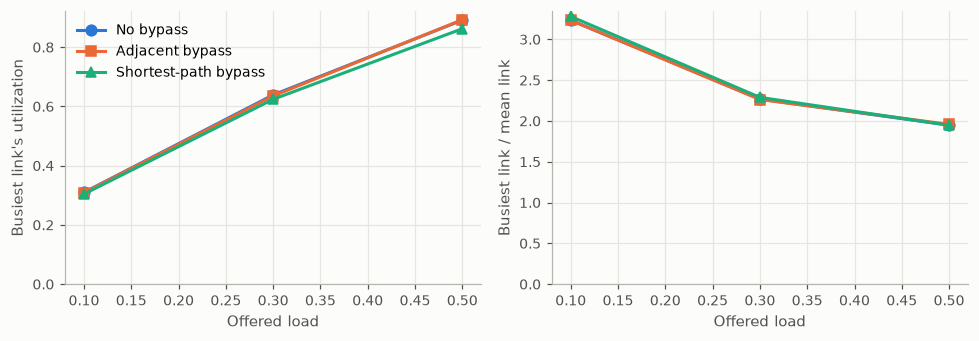

In [13]:
if ready:
    table = common.link_table(links, ["load", "bypass"])
    display(table)
    figure, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharex=True)
    for axis, column, label in zip(axes, ["max_utilization", "hotspot_ratio"], ["Busiest link's utilization", "Busiest link / mean link"]):
        for mode in common.MODES:
            group = table.xs(mode, level="bypass").reset_index() if mode in table.index.get_level_values("bypass") else None
            if group is None:
                continue
            axis.plot(group["load"], group[column], color=common.MODE_COLORS[mode], marker=common.MODE_MARKERS[mode], label=common.MODE_NAMES[mode])
        axis.set(xlabel="Offered load", ylabel=label, ylim=(0, None))
    axes[0].legend()
    figure.tight_layout()

### Which links got busier

The busiest link overall may not be the one the bypass loads, so this compares each link with itself in the baseline run. `links_busier` and `links_quieter` are the shares of links whose utilization moved by more than 1 point. The `top_` columns describe the 1% of links whose utilization rose the most. If the bypass creates hotspots, those links end up busier than the baseline's links and fill their queues more often than before.

In [14]:
if ready:
    paired_links = common.link_changes(links)
    display(common.hotspot_table(paired_links, ["load", "bypass"]))

links_busier  links_quieter  largest_gain  \
load bypass                                                
0.10 adjacent          0.00           0.00          0.00   
     shortest          0.00           0.00          0.00   
0.30 adjacent          0.01           0.01          0.02   
     shortest          0.01           0.42          0.02   
0.50 adjacent          0.07           0.08          0.06   
     shortest          0.02           0.72          0.05   

               top_utilization_before  top_utilization_after  \
load bypass                                                    
0.10 adjacent                    0.10                   0.10   
     shortest                    0.08                   0.08   
0.30 adjacent                    0.30                   0.32   
     shortest                    0.29                   0.30   
0.50 adjacent                    0.47                   0.50   
     shortest                    0.42                   0.44   

               top_filled_before  top_filled_after  
load bypass                                         
0.10 adjacent               0.01              0.01  
     shortest               0.00              0.00  
0.30 adjacent               0.23              0.24  
     shortest               0.21              0.20  
0.50 adjacent               0.48              0.50  
     shortest               0.33              0.38

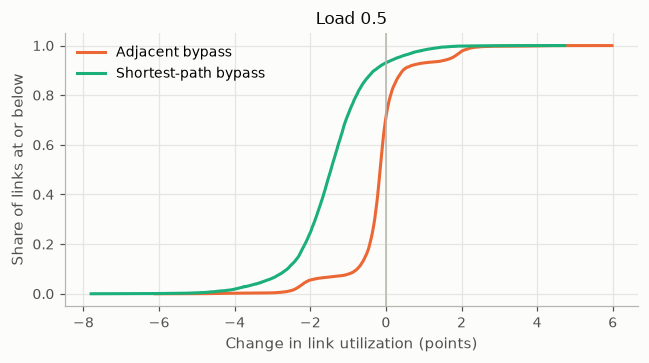

In [15]:
if ready:
    top_load = paired_links["load"].max()
    figure, axis = plt.subplots(figsize=(6, 3.4))
    for mode, group in paired_links[paired_links["load"] == top_load].groupby("bypass"):
        change = np.sort(group["utilization_change"].to_numpy()) * 100
        axis.plot(change, np.linspace(0, 1, len(change)), color=common.MODE_COLORS[mode], label=common.MODE_NAMES[mode])
    axis.axvline(0, color="#b5b4ad", linewidth=1)
    axis.set(xlabel="Change in link utilization (points)", ylabel="Share of links at or below", title=f"Load {top_load:g}")
    axis.legend()
    figure.tight_layout()

### Fan-in

Does the bypass concentrate a destination's traffic on fewer neighbors?

In [16]:
if ready:
    display(common.fan_in_table(links, ["load", "bypass"]))

busiest_share  neighbors
load bypass                            
0.10 adjacent           0.18      16.00
     none               0.18      16.00
     shortest           0.18      16.00
0.30 adjacent           0.13      16.00
     none               0.13      16.00
     shortest           0.13      16.00
0.50 adjacent           0.12      16.00
     none               0.12      16.00
     shortest           0.12      16.00

## H3: How many flows does it reach?

An adjacent-only bypass can only help small flows between neighboring routers. Comparing all small flows shows what that limit costs against bypassing everything.

In [17]:
if ready:
    small = flows[flows["class"] != "large"]
    print(f"Adjacent share of small flows: {(small['class'] == 'small_adjacent').mean():.1%}")
    display(common.fct_table(small.assign(group="all small"), ["group", "load", "bypass"]))

Adjacent share of small flows: 6.2%


flows  unfinished   p50      p99     p99.9  \
group     load bypass                                                  
all small 0.10 adjacent  101329           0 10.51    17.45     25.31   
               none      101329           0 10.51    17.51     25.63   
               shortest  101329           0  7.81    14.62     21.73   
          0.30 adjacent  303926           0 12.09    32.98  1,055.28   
               none      303926           0 12.22    33.28  1,062.77   
               shortest  303926           0  9.51    28.57  1,037.58   
          0.50 adjacent  507398           0 17.57 1,044.40 10,010.49   
               none      507398           0 17.99 1,047.92 10,010.49   
               shortest  507398           0 13.46    67.39 10,008.86   

                         beyond_p99  
group     load bypass                
all small 0.10 adjacent        1013  
               none            1013  
               shortest        1013  
          0.30 adjacent        3039  
               none            3039  
               shortest        3039  
          0.50 adjacent        5073  
               none            5073  
               shortest        5073